# cleaning.ipynb

*Contains Claude generated code*

Combine and reformat raw data for use in modeling further in the pipeline, then run
exploratory data analysis (EDA) on the cleaned dataset.

**Sections**
1. Setup
2. Cleaning
3. Data checks
4. EDA

## 1. Setup

In [1]:
# Globals for this file, need to be updated once
# a new season, or sport is added
SPORTS_SEASONS = {"nfl": [2025],
                  "mlb": [2025],
                  "nba": [2025],
                  "nhl": [2025]}

STATES = ["away", "home"]

# Games with less combined pre-kickoff volume than this are FLAGGED, not dropped.
# Their closing quotes may be stale, so analyses can exclude them as a robustness check.
MIN_VOLUME = 100

import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

sys.path.append("..")
from src.pricing.devig import devig_two_way, american_odds_to_prob

In [2]:
# Plot styling: one fixed color per sport, used in every figure
SPORT_COLORS = {"nfl": "#2a78d6", "mlb": "#eb6834", "nba": "#1baf7a", "nhl": "#eda100"}
SPORT_ORDER = list(SPORTS_SEASONS.keys())
INK, MUTED, GRID = "#2b2b29", "#6b6a64", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": INK,
    "font.size": 9.5,
    "lines.linewidth": 2,
    "legend.frameon": False,
})

## 2. Cleaning

Changes from the previous version of `clean_data`:

- **Adds `sport`, `home_win` and `month`.** All three are needed by the models (outcome for the
  logistic regression, sport and month controls for the gap regression). Games with a missing
  score or a tie are dropped, since they have no win/loss outcome.
- **Normalizes Kalshi's probabilities.** The home and away midpoints sum to about 1.01, so each
  side is divided by their sum (Kalshi's version of de-vigging). Without this, the home and away
  spreads were not mirror images of each other. The raw midpoints are kept as `kalshi_{side}_mid`.
- **Keeps the bid and ask columns.** The betting strategy needs the ask (the price you'd
  actually pay), and the bid-ask spread is itself a liquidity measure.
- **Flags low-volume games instead of silently dropping them.** The old `log(total_volume)`
  step removed every zero-volume game (the divide-by-zero warnings), which was at least a quarter of
  MLB. Logs now use `log(1 + x)` and those games carry a `low_volume` flag.
- **Adds the slide 8 regressors**: total open interest, `log_open_interest`, `log_volume`,
  `log_turnover`, `lopsided` and the absolute gap `abs_gap`.
- **Records how many rows each step drops**, for the data section of the report.

In [3]:
def read_season_data_file(sport: str, season: int) -> pd.DataFrame:
    """Read in .csv file from data directory and return dataframe containing the data"""
    if sport not in SPORTS_SEASONS.keys() or season not in SPORTS_SEASONS[sport]:
        raise ValueError("Dataset not currently available.")

    df = pd.read_csv(f"../data/{sport}_{season}_historical.csv")

    return df

In [4]:
def clean_data(df: pd.DataFrame, sport: str, de_vig_strat: str = "cheung",
               min_volume: float = MIN_VOLUME) -> tuple[pd.DataFrame, dict]:
    """Clean one sport's dataset for analysis.

    Returns the cleaned dataframe (one row per game) and a dict counting the rows
    removed at each step.
    """
    log = {"sport": sport, "raw_rows": len(df)}
    df = df.copy()
    df["sport"] = sport

    # Drop columns not needed downstream
    df = df.drop(columns=["game_id",
                          "kalshi_home_ticker",
                          "kalshi_away_ticker",
                          "kalshi_home_candle_end_ts",
                          "kalshi_away_candle_end_ts",
                          "sportsbook_bookmaker",
                          "kalshi_home_close_price",
                          "kalshi_away_close_price"], errors="ignore")

    # 1. Need both Kalshi quotes, liquidity, and both sportsbook odds
    required = []
    for state in STATES:
        required += [f"kalshi_{state}_yes_bid_close",
                     f"kalshi_{state}_yes_ask_close",
                     f"kalshi_{state}_volume",
                     f"kalshi_{state}_open_interest",
                     f"sportsbook_{state}_odds_american"]
    before = len(df)
    df = df.dropna(subset=required)
    log["dropped_missing_prices"] = before - len(df)

    # 2. Need a win/loss outcome
    before = len(df)
    df = df.dropna(subset=["home_score", "away_score"])
    df = df[df["home_score"] != df["away_score"]]
    log["dropped_no_outcome_or_tie"] = before - len(df)
    df["home_win"] = (df["home_score"] > df["away_score"]).astype(int)

    # 3. Kalshi: midpoint, bid-ask spread, then normalize so home + away = 1
    for state in STATES:
        bid = df[f"kalshi_{state}_yes_bid_close"]
        ask = df[f"kalshi_{state}_yes_ask_close"]
        df[f"kalshi_{state}_mid"] = (bid + ask) / 2
        df[f"kalshi_{state}_ba_spread"] = ask - bid

    df["kalshi_overround"] = df["kalshi_home_mid"] + df["kalshi_away_mid"]
    before = len(df)
    df = df[df["kalshi_overround"] > 0]
    log["dropped_empty_book"] = before - len(df)
    for state in STATES:
        df[f"Kalshi_{state}_prob"] = df[f"kalshi_{state}_mid"] / df["kalshi_overround"]

    # 4. Sportsbook: American odds -> implied probability -> de-vig
    df[[f"sportsbook_{STATES[0]}_prob", f"sportsbook_{STATES[1]}_prob"]] = df.apply(
        lambda row: devig_two_way(
            american_odds_to_prob(row[f"sportsbook_{STATES[0]}_odds_american"]),
            american_odds_to_prob(row[f"sportsbook_{STATES[1]}_odds_american"]),
            de_vig_strat=de_vig_strat,
        ),
        axis=1,
        result_type="expand",
    )
    df = df.drop(columns=[f"sportsbook_{state}_odds_american" for state in STATES])

    # 5. Gap between sources (sportsbook - Kalshi). After normalization the home and
    #    away spreads are exact mirror images, so abs_gap uses the home side.
    for state in STATES:
        df[f"{state}_prob_spread"] = df[f"sportsbook_{state}_prob"] - df[f"Kalshi_{state}_prob"]
    df["abs_gap"] = df["home_prob_spread"].abs()

    # Lopsided = |P(home) - P(away)|, using the average of the two sources
    p_home_avg = (df["Kalshi_home_prob"] + df["sportsbook_home_prob"]) / 2
    df["lopsided"] = (2 * p_home_avg - 1).abs()

    # 6. Liquidity variables (log(1 + x) so zero-volume games are kept)
    df["total_volume"] = df["kalshi_away_volume"] + df["kalshi_home_volume"]
    df["total_open_interest"] = df["kalshi_away_open_interest"] + df["kalshi_home_open_interest"]
    df["log_volume"] = np.log1p(df["total_volume"])
    df["log_open_interest"] = np.log1p(df["total_open_interest"])
    df["log_turnover"] = df["log_volume"] - df["log_open_interest"]   # log((1+V)/(1+OI))
    df["kalshi_ba_spread"] = (df["kalshi_home_ba_spread"] + df["kalshi_away_ba_spread"]) / 2
    df["low_volume"] = df["total_volume"] < min_volume

    # 7. Time variables
    df["start_time_utc"] = pd.to_datetime(df["start_time_utc"], utc=True)
    df["month"] = df["start_time_utc"].dt.strftime("%Y-%m")

    log["final_rows"] = len(df)
    log["low_volume_rows"] = int(df["low_volume"].sum())

    df = df.sort_values(by="start_time_utc").reset_index(drop=True)
    return df, log

In [5]:
# Read and clean all sports for 2025 season
raw = {}
clean = {}
logs = []

for sport in SPORTS_SEASONS.keys():
    raw[sport] = read_season_data_file(sport, 2025)
    clean[sport], log = clean_data(raw[sport], sport)
    logs.append(log)

retention = pd.DataFrame(logs).set_index("sport")
retention.loc["total"] = retention.sum()
retention["kept_%"] = (100 * retention["final_rows"] / retention["raw_rows"]).round(1)
retention

,raw_rows,dropped_missing_prices,dropped_no_outcome_or_tie,dropped_empty_book,final_rows,low_volume_rows,kept_%
sport,,,,,,,
nfl,281,4,1,0,276,0,98.2
mlb,2166,156,19,0,1991,1008,91.9
nba,1320,105,1,0,1214,12,92.0
nhl,1393,9,0,0,1384,182,99.4
total,5160,274,21,0,4865,1202,94.3


In [6]:
df_clean = pd.concat(clean.values(), ignore_index=True)
df_clean = df_clean.sort_values(by="start_time_utc", ascending=True).reset_index(drop=True)

# Sanity checks: normalized probabilities sum to 1 and spreads mirror each other
assert np.allclose(df_clean["Kalshi_home_prob"] + df_clean["Kalshi_away_prob"], 1)
assert np.allclose(df_clean["home_prob_spread"], -df_clean["away_prob_spread"], atol=1e-9)

print(df_clean.shape)
df_clean.head()

(4865, 36)


,home_team,away_team,start_time_utc,home_score,away_score,kalshi_home_yes_bid_close,kalshi_home_yes_ask_close,kalshi_home_volume,kalshi_home_open_interest,kalshi_away_yes_bid_close,...,abs_gap,lopsided,total_volume,total_open_interest,log_volume,log_open_interest,log_turnover,kalshi_ba_spread,low_volume,month
0,Toronto Blue Jays,Atlanta Braves,2025-04-16 17:07:00+00:00,3.0,1.0,0.44,0.49,0.0,50.0,0.51,...,0.007667,0.077667,483.0,1537.0,6.182085,7.338238,-1.156153,0.050,False,2025-04
1,Minnesota Twins,New York Mets,2025-04-16 17:10:00+00:00,4.0,3.0,0.50,0.54,1.0,1.0,0.46,...,0.002478,0.048027,50.0,332.0,3.931826,5.808142,-1.876317,0.030,True,2025-04
2,Milwaukee Brewers,Detroit Tigers,2025-04-16 17:10:00+00:00,5.0,1.0,0.56,0.59,1.0,3.0,0.40,...,0.003689,0.157928,23.0,186.0,3.178054,5.231109,-2.053055,0.030,True,2025-04
3,San Diego Padres,Chicago Cubs,2025-04-16 20:10:00+00:00,4.0,2.0,0.50,0.53,46.0,2147.0,0.48,...,0.010337,0.035212,46.0,4898.0,3.850148,8.496786,-4.646639,0.025,True,2025-04
4,Baltimore Orioles,Cleveland Guardians,2025-04-16 22:35:00+00:00,9.0,1.0,0.53,0.55,75.0,1032.0,0.45,...,0.006061,0.073939,75.0,2348.0,4.330733,7.761745,-3.431012,0.020,True,2025-04


In [7]:
print(df_clean.dtypes)

home_team                                    str
away_team                                    str
start_time_utc               datetime64[us, UTC]
home_score                               float64
away_score                               float64
kalshi_home_yes_bid_close                float64
kalshi_home_yes_ask_close                float64
kalshi_home_volume                       float64
kalshi_home_open_interest                float64
kalshi_away_yes_bid_close                float64
kalshi_away_yes_ask_close                float64
kalshi_away_volume                       float64
kalshi_away_open_interest                float64
sport                                        str
home_win                                   int64
kalshi_away_mid                          float64
kalshi_away_ba_spread                    float64
kalshi_home_mid                          float64
kalshi_home_ba_spread                    float64
kalshi_overround                         float64
Kalshi_away_prob    

In [8]:
df_clean.to_csv("../data/clean_data.csv", index=False)

## 3. Data checks

Checks on the raw data that affect how the liquidity variables should be read.

In [9]:
# What does the "volume" column measure?
# Cumulative volume over a market's life must be at least its open interest.
# If volume is almost always far below open interest, the column is the volume
# inside the pre-kickoff candle window, not cumulative volume.
# Also check units: whole-number volumes suggest contracts, decimals suggest
# a fixed-point or dollar field.
checks = []
for s, df in raw.items():
    v = df["kalshi_home_volume"] + df["kalshi_away_volume"]
    oi = df["kalshi_home_open_interest"] + df["kalshi_away_open_interest"]
    ok = v.notna() & oi.notna()
    checks.append({
        "sport": s,
        "share_volume_gt_OI_%": round(100 * (v[ok] > oi[ok]).mean(), 1),
        "median_volume_to_OI": round((v[ok] / oi[ok].replace(0, np.nan)).median(), 4),
        "share_non_integer_volume_%": round(100 * (v[ok] % 1 != 0).mean(), 1),
    })
pd.DataFrame(checks).set_index("sport")

,share_volume_gt_OI_%,median_volume_to_OI,share_non_integer_volume_%
sport,,,
nfl,0.0,0.0113,0.0
mlb,0.0,0.0034,0.0
nba,0.0,0.0080,6.1
nhl,0.0,0.0056,6.0


**How to read this.** If `share_volume_gt_OI_%` is near 0, `volume` is the volume traded in
the final pre-kickoff candle window, not over the market's life. Turnover (volume ÷ open
interest) then means "how actively the price was traded right before kickoff," which is
the staleness measure discussed for the methodology. Describe it that way on slide 8.

If `share_non_integer_volume_%` is 0 for some sports and large for others, the pipeline may
have pulled differently defined fields across sports (e.g. whole contracts vs. a fixed-point
field). Confirm in `historical_snapshot.py` before pooling volumes across sports. Sport fixed
effects absorb a constant unit difference in levels, but not in the slope of log volume.

**Result of the volume-units check (resolved 2026-11-05).** The non-integer volumes in NBA and NHL are a date effect, not a sport effect. Every NBA and NHL game up to April 16, 2026 has whole-number volume and open interest; from April 16–17, 2026 onward almost every game has fractional values (e.g. 13,043.12 contracts). That matches Kalshi starting to allow fractional contract sizes around then. NFL (season over in January) and MLB (over in November 2025) never reach that date, which is why they show 0%.

The units are the same throughout: contracts. Open interest runs continuously across the switch (NBA games either side of April 16 have about 1–2.5 million contracts open), so there's no change of scale and pooling across sports is fine. The switch coincides with the start of the NBA and NHL playoffs, so the `postseason` control absorbs any level shift at that date.

In [10]:
# Does the price candle end exactly at kickoff? (minutes between candle end and start time)
for s, df in raw.items():
    ts = pd.to_datetime(df["kalshi_home_candle_end_ts"], unit="s", utc=True)
    gap_min = (pd.to_datetime(df["start_time_utc"], utc=True) - ts).dt.total_seconds() / 60
    print(s, gap_min.describe()[["min", "50%", "max"]].round(1).to_dict())

nfl {'min': 0.0, '50%': 0.0, 'max': 0.0}
mlb {'min': 0.0, '50%': 0.0, 'max': 27.0}
nba {'min': 0.0, '50%': 0.0, 'max': 0.0}
nhl {'min': 0.0, '50%': 0.0, 'max': 2.0}


In [11]:
# Inspecting low volume values...
for s, df in raw.items():
    v = df["kalshi_home_volume"] + df["kalshi_away_volume"]
    print(s, v.describe(percentiles=[.01, .05, .25, .5]).round(0).to_dict())
    print(f"  combined volume < {MIN_VOLUME}:", (v < MIN_VOLUME).sum(), "of", v.notna().sum())

nfl {'count': 279.0, 'mean': 52257.0, 'std': 54242.0, 'min': 487.0, '1%': 1310.0, '5%': 2974.0, '25%': 14202.0, '50%': 37742.0, 'max': 324346.0}
  combined volume < 100: 0 of 279
mlb {'count': 2150.0, 'mean': 1379.0, 'std': 6138.0, 'min': 0.0, '1%': 0.0, '5%': 0.0, '25%': 0.0, '50%': 90.0, 'max': 110633.0}
  combined volume < 100: 1107 of 2150
nba {'count': 1320.0, 'mean': 16918.0, 'std': 33497.0, 'min': 0.0, '1%': 141.0, '5%': 501.0, '25%': 2085.0, '50%': 6039.0, 'max': 483090.0}
  combined volume < 100: 12 of 1320
nhl {'count': 1393.0, 'mean': 3023.0, 'std': 8743.0, 'min': 0.0, '1%': 0.0, '5%': 23.0, '25%': 251.0, '50%': 732.0, 'max': 145017.0}
  combined volume < 100: 183 of 1393


In [12]:
# Lowest-volume NBA games: do their quotes still look sensible?
df = raw["nba"].copy()
df["vol"] = df["kalshi_home_volume"] + df["kalshi_away_volume"]
cols = ["start_time_utc", "home_team", "away_team", "vol",
        "kalshi_home_yes_bid_close", "kalshi_home_yes_ask_close",
        "kalshi_away_yes_bid_close", "kalshi_away_yes_ask_close"]
df.nsmallest(15, "vol")[cols]

,start_time_utc,home_team,away_team,vol,kalshi_home_yes_bid_close,kalshi_home_yes_ask_close,kalshi_away_yes_bid_close,kalshi_away_yes_ask_close
5,2026-05-31T00:00Z,Oklahoma City Thunder,San Antonio Spurs,0.0,0.56,0.57,0.42,0.43
1181,2025-11-09T02:00Z,Denver Nuggets,Indiana Pacers,18.0,0.80,0.81,0.19,0.20
159,2026-04-04T00:00Z,Houston Rockets,Utah Jazz,37.0,0.93,0.94,0.06,0.07
923,2025-12-19T01:00Z,Milwaukee Bucks,Toronto Raptors,40.0,0.37,0.38,0.62,0.64
1316,2025-10-23T00:00Z,Milwaukee Bucks,Washington Wizards,50.0,0.79,0.80,0.20,0.21
909,2025-12-21T00:00Z,New Orleans Pelicans,Indiana Pacers,51.0,0.56,0.57,0.43,0.45
740,2026-01-12T01:00Z,Phoenix Suns,Washington Wizards,60.0,0.86,0.88,0.13,0.14
139,2026-04-07T23:00Z,Indiana Pacers,Minnesota Timberwolves,82.0,0.13,0.14,0.86,0.87
194,2026-03-31T00:00Z,Memphis Grizzlies,Phoenix Suns,85.0,0.13,0.14,0.86,0.87
350,2026-03-11T02:00Z,Sacramento Kings,Indiana Pacers,88.0,0.59,0.60,0.41,0.42


## 4. Exploratory data analysis

Each figure previews one part of the methodology:

| Figure | Shows | Previews |
|---|---|---|
| Summary table | Sample, liquidity and prices by sport | Data section |
| 1 | Liquidity distributions by sport | Gap regression (slide 8) |
| 2 | Liquidity over time | Why the month controls are needed |
| 3 | Kalshi vs. sportsbook probabilities | How close the two sources are |
| 4 | Distribution of the gap | Gap regression's dependent variable; betting thresholds |
| 5 | Gap vs. open interest | Gap regression, coefficient on log open interest |
| 6 | Correlation between regressors | Which regressors are redundant |
| 7 | Calibration of both sources | Logistic regression (slide 7) |

In [13]:
# Summary by sport
g = df_clean.groupby("sport")
summary = pd.DataFrame({
    "games": g.size(),
    "low_volume_%": 100 * g["low_volume"].mean(),
    "median_open_interest": g["total_open_interest"].median(),
    "median_volume": g["total_volume"].median(),
    "median_kalshi_overround": g["kalshi_overround"].median(),
    "median_bid_ask_spread_c": 100 * g["kalshi_ba_spread"].median(),
    "median_abs_gap_pp": 100 * g["abs_gap"].median(),
    "home_prob_p10": g["Kalshi_home_prob"].quantile(0.10),
    "home_prob_p90": g["Kalshi_home_prob"].quantile(0.90),
    "home_win_rate": g["home_win"].mean(),
}).reindex(SPORT_ORDER)
summary.round(3)

,games,low_volume_%,median_open_interest,median_volume,median_kalshi_overround,median_bid_ask_spread_c,median_abs_gap_pp,home_prob_p10,home_prob_p90,home_win_rate
sport,,,,,,,,,,
nfl,276,0.000,2411295.5,36270.0,1.0,1.0,0.678,0.275,0.806,0.533
mlb,1991,50.628,26029.0,96.0,1.0,1.0,0.637,0.409,0.658,0.532
nba,1214,0.988,719499.0,5879.0,1.0,1.0,0.610,0.225,0.847,0.554
nhl,1384,13.150,136570.0,728.0,1.0,1.0,0.526,0.415,0.651,0.520


`home_prob_p10` and `home_prob_p90` show how spread out each sport's prices are. A narrow range
(likely NHL and MLB) means fewer heavy favorites and longshots, so less power to detect a
favorite-longshot bias in that sport. That's the reason to pool sports in the logistic regression.

In [14]:
# Key variables
df_clean[["abs_gap", "home_prob_spread", "total_volume", "total_open_interest",
          "log_volume", "log_open_interest", "log_turnover", "lopsided",
          "kalshi_ba_spread"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
abs_gap,4865.0,0.007,0.006,0.000,0.002,0.006,0.010,8.400000e-02
home_prob_spread,4865.0,0.001,0.009,-0.084,-0.005,0.001,0.008,5.000000e-02
total_volume,4865.0,8597.093,25473.578,0.000,101.000,856.000,4906.000,4.830900e+05
total_open_interest,4865.0,606311.382,1628039.611,186.000,31824.000,115354.000,505903.000,3.756932e+07
log_volume,4865.0,6.272,3.124,0.000,4.625,6.753,8.498,1.308800e+01
log_open_interest,4865.0,11.756,1.823,5.231,10.368,11.656,13.134,1.744200e+01
log_turnover,4865.0,-5.483,2.068,-12.175,-6.397,-5.105,-4.126,-3.200000e-01
lopsided,4865.0,0.232,0.196,0.000,0.090,0.179,0.319,9.550000e-01
kalshi_ba_spread,4865.0,0.012,0.004,0.010,0.010,0.010,0.010,8.000000e-02


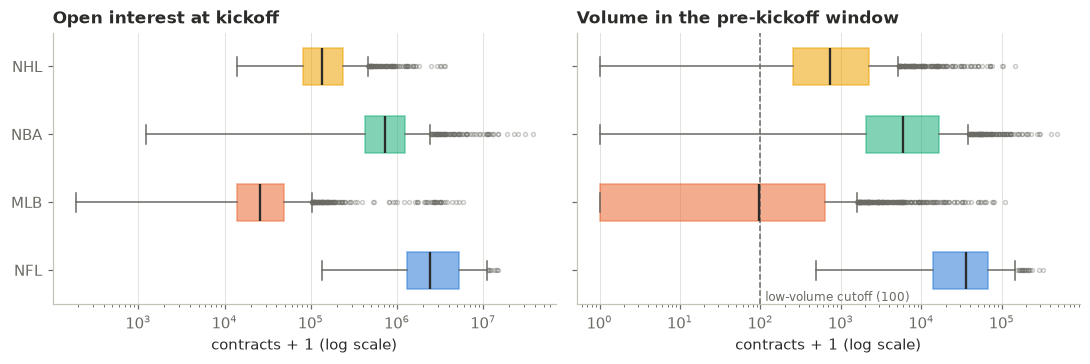

In [15]:
# Figure 1: Liquidity distributions by sport (log scale)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
panels = [("total_open_interest", "Open interest at kickoff"),
          ("total_volume", "Volume in the pre-kickoff window")]

for ax, (col, title) in zip(axes, panels):
    data = [df_clean.loc[df_clean["sport"] == s, col] + 1 for s in SPORT_ORDER]
    bp = ax.boxplot(data, orientation="horizontal", patch_artist=True, widths=0.55,
                    medianprops={"color": INK, "linewidth": 1.5},
                    whiskerprops={"color": MUTED}, capprops={"color": MUTED},
                    flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.35,
                                "markeredgecolor": MUTED})
    for patch, s in zip(bp["boxes"], SPORT_ORDER):
        patch.set_facecolor(SPORT_COLORS[s])
        patch.set_alpha(0.55)
        patch.set_edgecolor(SPORT_COLORS[s])
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("contracts + 1 (log scale)")
    ax.grid(axis="y", visible=False)

axes[0].set_yticks(range(1, len(SPORT_ORDER) + 1), [s.upper() for s in SPORT_ORDER])
axes[1].axvline(MIN_VOLUME, color=MUTED, ls="--", lw=1)
axes[1].text(MIN_VOLUME * 1.15, 0.6, f"low-volume cutoff ({MIN_VOLUME})",
             color=MUTED, fontsize=8, va="center")
fig.tight_layout()
plt.show()

**What to look for:** how much liquidity differs between sports (likely orders of magnitude, NFL
and NBA above NHL and MLB) and how many games sit left of the cutoff. Because sport explains so
much of the liquidity variation, the sport controls in the gap regression matter. Without them,
the open-interest coefficient would partly measure "NFL vs. MLB."

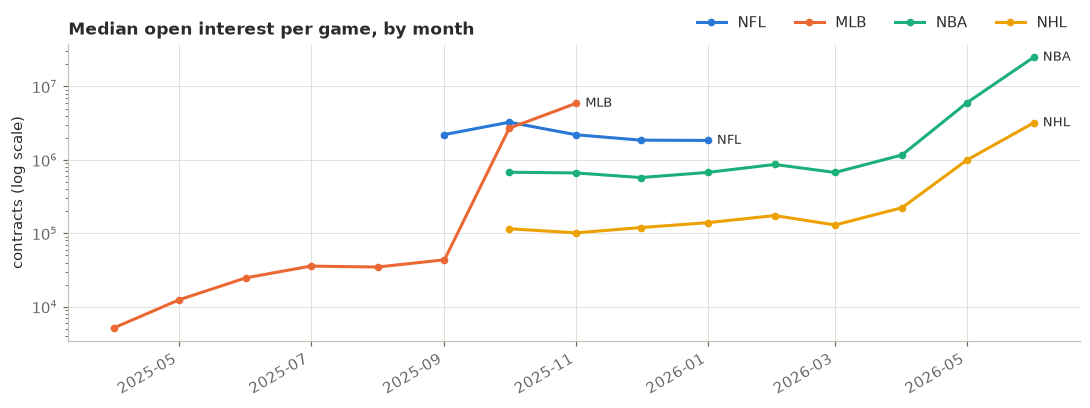

In [16]:
# Figure 2: Monthly median open interest by sport
monthly = (df_clean.groupby(["sport", "month"])["total_open_interest"]
           .median().reset_index())
monthly["month_dt"] = pd.to_datetime(monthly["month"])

fig, ax = plt.subplots(figsize=(10, 3.8))
for s in SPORT_ORDER:
    m = monthly[monthly["sport"] == s].sort_values("month_dt")
    if m.empty:
        continue
    ax.plot(m["month_dt"], m["total_open_interest"], marker="o", markersize=4,
            color=SPORT_COLORS[s], label=s.upper())
    last = m.iloc[-1]
    ax.annotate(s.upper(), (last["month_dt"], last["total_open_interest"]),
                xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=INK)

ax.set_yscale("log")
ax.set_title("Median open interest per game, by month")
ax.set_ylabel("contracts (log scale)")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=4)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

**What to look for:** an upward trend within each sport (platform growth) and jumps at playoff
time. Both change liquidity for reasons unrelated to any one game, which is why the gap
regression includes month controls. Without them, "liquid games have smaller gaps" could just
mean "later games have smaller gaps."

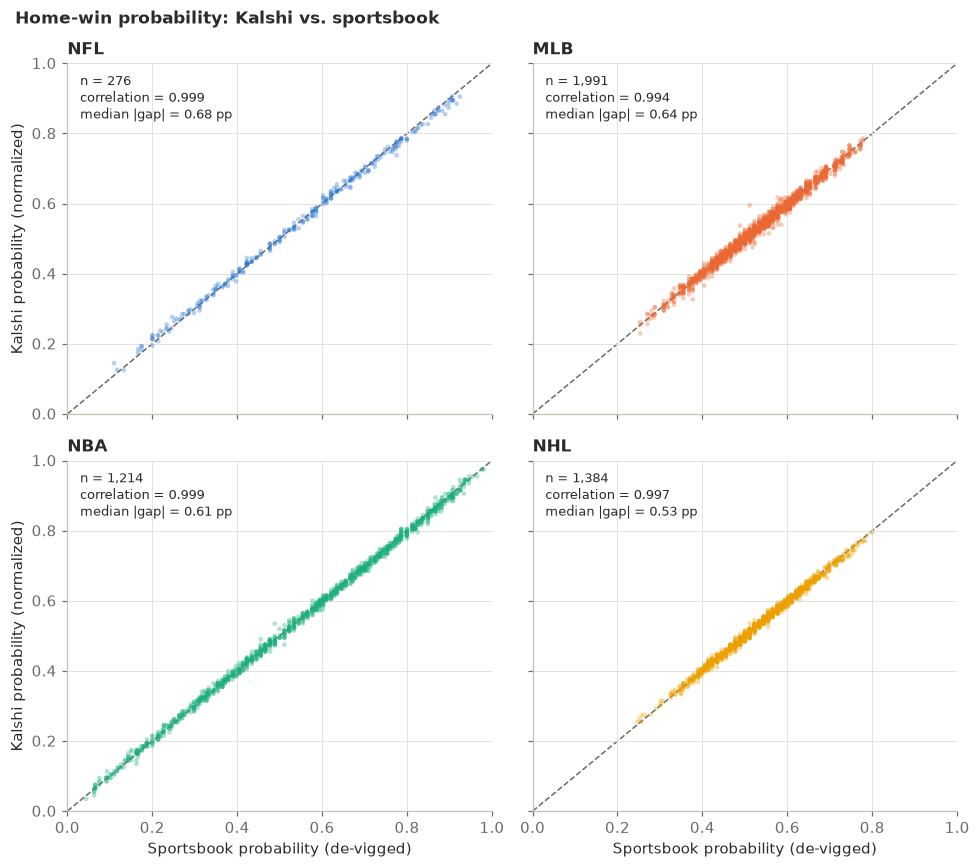

In [17]:
# Figure 3: Kalshi vs. sportsbook home-win probability
fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True)

for ax, s in zip(axes.flat, SPORT_ORDER):
    d = df_clean[df_clean["sport"] == s]
    ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, zorder=1)
    ax.scatter(d["sportsbook_home_prob"], d["Kalshi_home_prob"], s=9, alpha=0.35,
               color=SPORT_COLORS[s], edgecolors="none", zorder=2)
    r = d["sportsbook_home_prob"].corr(d["Kalshi_home_prob"])
    ax.text(0.03, 0.97,
            f"n = {len(d):,}\ncorrelation = {r:.3f}\nmedian |gap| = {100 * d['abs_gap'].median():.2f} pp",
            transform=ax.transAxes, va="top", fontsize=8.5, color=INK)
    ax.set_title(s.upper())
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

for ax in axes[1]:
    ax.set_xlabel("Sportsbook probability (de-vigged)")
for ax in axes[:, 0]:
    ax.set_ylabel("Kalshi probability (normalized)")
fig.suptitle("Home-win probability: Kalshi vs. sportsbook", x=0.02, ha="left",
             fontweight="bold")
fig.tight_layout()
plt.show()

**What to look for:** points hugging the dashed 45° line mean the two sources agree. Points far
off the line are either real disagreements or data problems (a stale quote, a mismatched game),
so they're worth inspecting individually before modeling.

In [18]:
# The largest disagreements, to inspect by hand
cols = ["sport", "start_time_utc", "home_team", "away_team", "Kalshi_home_prob",
        "sportsbook_home_prob", "home_prob_spread", "total_volume",
        "kalshi_ba_spread", "low_volume"]
df_clean.nlargest(10, "abs_gap")[cols]

,sport,start_time_utc,home_team,away_team,Kalshi_home_prob,sportsbook_home_prob,home_prob_spread,total_volume,kalshi_ba_spread,low_volume
428,mlb,2025-05-24 20:10:00+00:00,Atlanta Braves,San Diego Padres,0.595000,0.511370,-0.083630,0.0,0.010,True
186,mlb,2025-05-04 01:38:00+00:00,Los Angeles Angels,Detroit Tigers,0.326633,0.377035,0.050402,2853.0,0.015,False
306,mlb,2025-05-14 01:45:00+00:00,San Francisco Giants,Arizona Diamondbacks,0.537313,0.488630,-0.048683,5530.0,0.015,False
3537,nba,2026-01-14 03:30:00+00:00,Los Angeles Lakers,Atlanta Hawks,0.535000,0.488630,-0.046370,115369.0,0.010,False
344,mlb,2025-05-17 20:05:00+00:00,Baltimore Orioles,Washington Nationals,0.540000,0.585908,0.045908,10.0,0.020,True
426,mlb,2025-05-24 20:05:00+00:00,Pittsburgh Pirates,Milwaukee Brewers,0.475000,0.518206,0.043206,0.0,0.010,True
325,mlb,2025-05-16 00:05:00+00:00,Texas Rangers,Houston Astros,0.515000,0.556578,0.041578,116.0,0.010,False
533,mlb,2025-06-01 21:10:00+00:00,San Diego Padres,Pittsburgh Pirates,0.617647,0.577120,-0.040528,1658.0,0.040,False
2268,nfl,2025-10-26 17:00:00+00:00,Atlanta Falcons,Miami Dolphins,0.737624,0.775518,0.037895,57371.0,0.010,False
123,mlb,2025-04-29 22:35:00+00:00,Baltimore Orioles,New York Yankees,0.366337,0.404158,0.037821,298.0,0.030,False


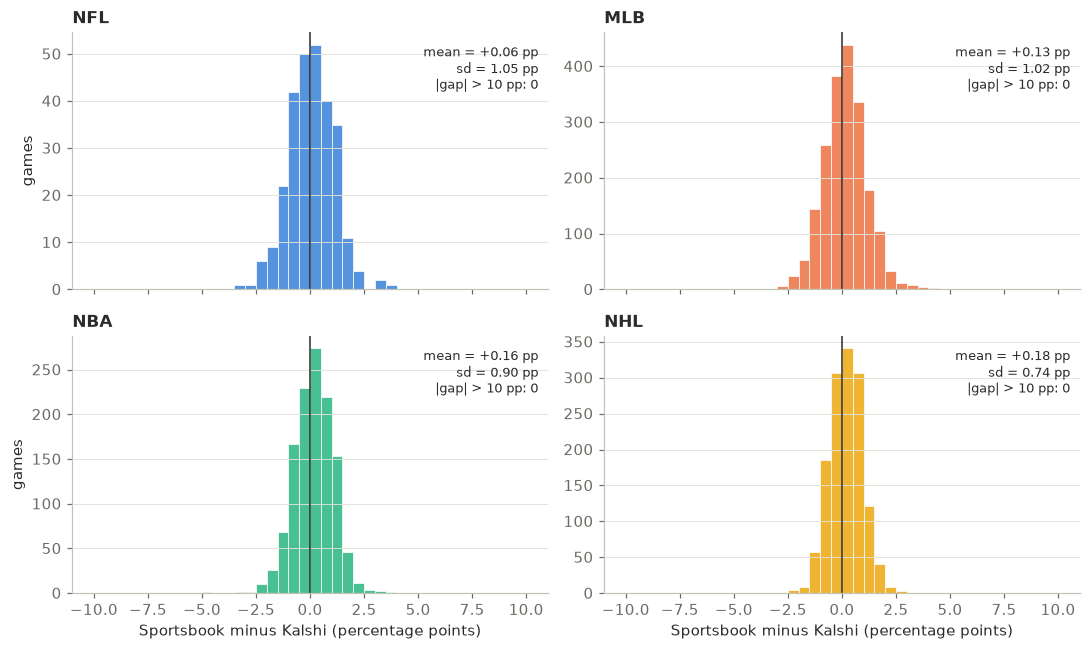

In [19]:
# Figure 4: Distribution of the gap (sportsbook - Kalshi, home side), percentage points
CLIP = 10
bins = np.arange(-CLIP, CLIP + 0.5, 0.5)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)

for ax, s in zip(axes.flat, SPORT_ORDER):
    x = 100 * df_clean.loc[df_clean["sport"] == s, "home_prob_spread"]
    outside = (x.abs() > CLIP).sum()
    ax.hist(x.clip(-CLIP, CLIP), bins=bins, color=SPORT_COLORS[s], alpha=0.8,
            edgecolor="white", linewidth=0.6)
    ax.axvline(0, color=INK, lw=1)
    ax.text(0.98, 0.95,
            f"mean = {x.mean():+.2f} pp\nsd = {x.std():.2f} pp\n|gap| > {CLIP} pp: {outside}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK)
    ax.set_title(s.upper())
    ax.grid(axis="x", visible=False)

for ax in axes[1]:
    ax.set_xlabel("Sportsbook minus Kalshi (percentage points)")
for ax in axes[:, 0]:
    ax.set_ylabel("games")
fig.tight_layout()
plt.show()

**What to look for:**
- **Mean away from 0:** a systematic tilt, e.g. Kalshi pricing home teams consistently higher
  or lower than sportsbooks.
- **Spread (sd):** sets realistic betting thresholds. If almost every gap is under 2 pp, a grid
  of thresholds running to 10 pp will place almost no bets at the top end.
- **Tails:** few games with large gaps means a high-threshold strategy rests on a small sample.

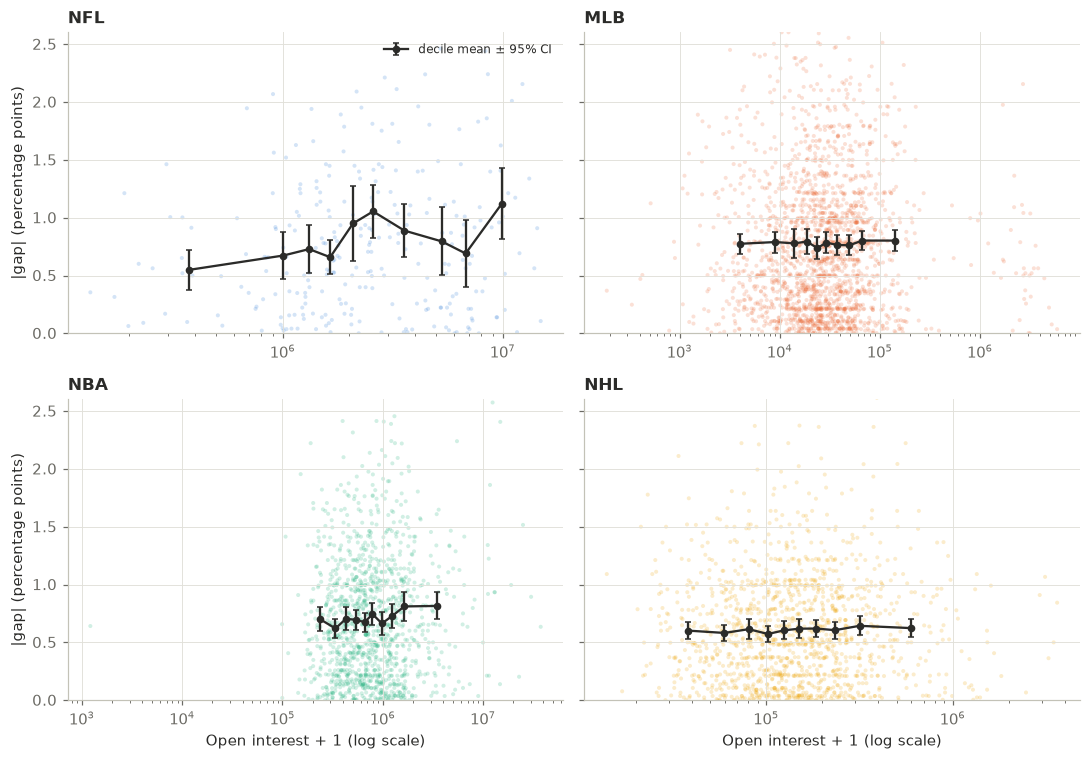

In [20]:
# Figure 5: Absolute gap vs. open interest, with binned means
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)

for ax, s in zip(axes.flat, SPORT_ORDER):
    d = df_clean[df_clean["sport"] == s]
    ax.scatter(d["total_open_interest"] + 1, 100 * d["abs_gap"], s=7, alpha=0.2,
               color=SPORT_COLORS[s], edgecolors="none")

    # Mean |gap| within open-interest deciles, with 95% confidence intervals
    bins_ = pd.qcut(d["log_open_interest"], q=10, duplicates="drop")
    b = d.groupby(bins_, observed=True).agg(
        x=("total_open_interest", "median"),
        mean=("abs_gap", "mean"),
        se=("abs_gap", lambda v: v.std() / np.sqrt(len(v))),
    )
    ax.errorbar(b["x"] + 1, 100 * b["mean"], yerr=100 * 1.96 * b["se"],
                color=INK, marker="o", markersize=4, lw=1.5, capsize=2,
                label="decile mean ± 95% CI")
    ax.set_xscale("log")
    ax.set_ylim(0, np.nanpercentile(100 * df_clean["abs_gap"], 99))
    ax.set_title(s.upper())

for ax in axes[1]:
    ax.set_xlabel("Open interest + 1 (log scale)")
for ax in axes[:, 0]:
    ax.set_ylabel("|gap| (percentage points)")
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

**What to look for:** the black line sloping down means deeper markets agree more closely with
sportsbooks, the relationship that b₁ in the gap regression tests. The y-axis is capped at the
99th percentile so a few outliers don't flatten the plot. This is a raw relationship without
the controls, so treat it as a preview, not a result.

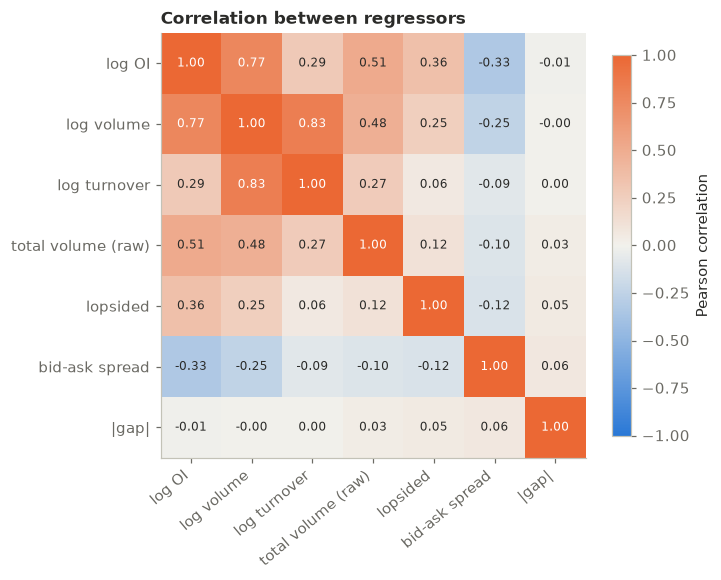

In [21]:
# Figure 6: Correlation between candidate regressors
reg_cols = {
    "log_open_interest": "log OI",
    "log_volume": "log volume",
    "log_turnover": "log turnover",
    "total_volume": "total volume (raw)",
    "lopsided": "lopsided",
    "kalshi_ba_spread": "bid-ask spread",
    "abs_gap": "|gap|",
}
corr = df_clean[list(reg_cols)].corr().rename(index=reg_cols, columns=reg_cols)

cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f2f1ec", "#eb6834"])
fig, ax = plt.subplots(figsize=(6.6, 5.6))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation between regressors")
fig.tight_layout()
plt.show()

**What to look for:** pairs with |r| above about 0.8 carry nearly the same information. If
`total volume (raw)` is strongly correlated with `log volume` and `log OI`, it adds little to the
slide 8 model and makes the coefficients unstable. That supports replacing b₃ with the
televised-game indicator or dropping it. Also check the bid-ask spread: if it's strongly
correlated with log OI, it's a candidate alternative liquidity measure for a robustness check.

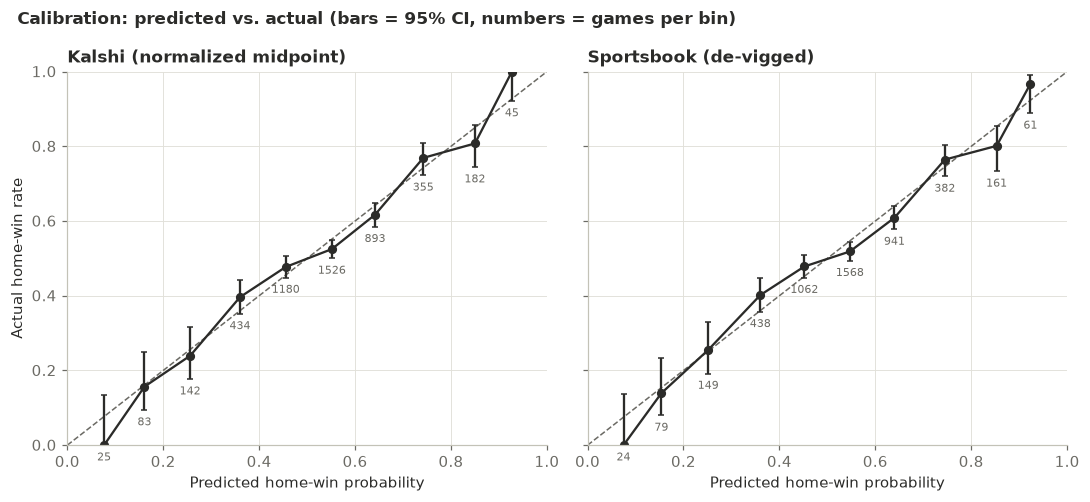

In [22]:
# Figure 7: Calibration (reliability diagram) for each source, all sports pooled
def calibration_table(p, y, n_bins=10):
    """Mean predicted probability, actual win rate, and 95% CI per probability bin."""
    edges = np.linspace(0, 1, n_bins + 1)
    b = pd.cut(p, edges, include_lowest=True)
    t = pd.DataFrame({"p": p, "y": y}).groupby(b, observed=True).agg(
        pred=("p", "mean"), actual=("y", "mean"), n=("y", "size"))
    # Wilson score interval (stays sensible when a bin's win rate is 0 or 1)
    z, n, ph = 1.96, t["n"], t["actual"]
    centre = (ph + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    t["lo"], t["hi"] = centre - half, centre + half
    return t[t["n"] >= 10]   # skip near-empty bins

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
sources = [("Kalshi_home_prob", "Kalshi (normalized midpoint)"),
           ("sportsbook_home_prob", "Sportsbook (de-vigged)")]

for ax, (col, title) in zip(axes, sources):
    t = calibration_table(df_clean[col], df_clean["home_win"])
    ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
    yerr = [t["actual"] - t["lo"], t["hi"] - t["actual"]]
    ax.errorbar(t["pred"], t["actual"], yerr=yerr, color=INK, marker="o",
                markersize=5, lw=1.5, capsize=2)
    for _, row in t.iterrows():
        ax.annotate(f"{int(row['n'])}", (row["pred"], row["lo"]),
                    xytext=(0, -10), textcoords="offset points", ha="center",
                    fontsize=7, color=MUTED)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("Predicted home-win probability")

axes[0].set_ylabel("Actual home-win rate")
fig.suptitle("Calibration: predicted vs. actual (bars = 95% CI, numbers = games per bin)",
             x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**What to look for:** points on the dashed line mean the prices are well calibrated. If points
fall *below* the line on the left and *above* it on the right, outcomes are more extreme than
prices, which is the favorite-longshot pattern (β > 1 in the logistic regression). The opposite
tilt means the market is overconfident (β < 1). Wide error bars in the outer bins are expected;
that's why the logistic regression, which uses every game at once, is the formal test rather
than this plot.